# NB5d — sensor and satellite rows on the validation units (development)

Guide §4.2 and the ablation table; D32 (index sources), D51 (learner). Development data only: the 10 validation units, NB5a's origins and slots. Reads `results/nb4_sensor/` and `results/nb5a_dev/`; writes `results/nb5d_sources/`.

**Rows (fixed before any number below):**
- **A4**: the LightGBM bank (part 2a setting, change from persistence, D34) on the raw pyranometer index;
- **A4b**: the same on the corrected pyranometer index (causal monthly calibration, D32);
- **A9**: the satellite (CAMS) index persisted forward; **A9n**: its same-time value (oracle, not a forecast).

Features and targets come from the source alone; the fleet fields σ, c and n are left empty. The issue and target rules are the fleet's. Gains: NB4's donor gains refitted against each source up to the event start; the prior is G2 (G0 = the median donor gain for a metadata-error target), recomputed here and checked against NB4's. Each row is scored on NB5a's slots where it has a forecast, and fleet LightGBM (NB5a, same seed) is scored on exactly the same slots, so every comparison is paired.

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
from scipy.stats import wilcoxon
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / 'tools'))
os.environ['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + os.environ.get('PYTHONPATH', '')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
from joblib import Parallel, delayed
from pvcold import config as C, audit as A, fleet as F, forecast as FC
import r1_score as R                      # NB5a context and slots (D37)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
N_JOBS = os.cpu_count(); t0 = time.time()
ctx = R.load_context()
p, E, U, geo15, gains3 = ctx['p'], ctx['E'], ctx['U'], ctx['geo15'], ctx['gains3']
PRIOR, ALT, VAL, fc5, idx, nb5 = ctx['PRIOR'], ctx['ALT'], ctx['VAL'], ctx['fc5'], ctx['idx'], ctx['nb5']
QC = R.QC
LGB_TEXT = (C.RESULTS / 'nb5a_dev' / 'lgb_config_part2a.yaml').read_bytes().decode('utf-8')
assert hashlib.sha256(LGB_TEXT.encode()).hexdigest() == nb5['lgb_config_sha256'], 'LightGBM config changed'
LGB_PARAMS = yaml.safe_load(LGB_TEXT)['lgb_params']
nb4 = json.loads((C.RESULTS / 'nb4_sensor' / 'summary.json').read_text())
SENS = (C.RESULTS / 'nb4_sensor' / 'sensor_config.yaml').read_bytes()
assert hashlib.sha256(SENS).hexdigest() == nb4['sensor_config_sha256'], 'sensor settings changed'
K15 = pd.read_parquet(C.RESULTS / 'nb4_sensor' / 'index15.parquet').set_index('time')
GX = pd.read_csv(C.RESULTS / 'nb4_sensor' / 'gains_external.csv')
PX = pd.read_csv(C.RESULTS / 'nb4_sensor' / 'priors_external.csv')
SOURCES = {'sensor_raw': ('LGB',), 'sensor_corr': ('LGB',), 'cams': ('A1', 'A7')}
ROWS = {'A4': ('sensor_raw', 'LGB'), 'A4b': ('sensor_corr', 'LGB'), 'A9': ('cams', 'A1'), 'A9n': ('cams', 'A7')}
print('LightGBM', LGB_PARAMS, '| prior', PRIOR, '| sources', list(SOURCES), '| rows', list(ROWS))

LightGBM {'learning_rate': 0.05, 'min_data_in_leaf': 200, 'num_leaves': 31} | prior G2 | sources ['sensor_raw', 'sensor_corr', 'cams'] | rows ['A4', 'A4b', 'A9', 'A9n']


## Forecasts: every validation unit, origin and source

In [2]:
tasks = []
for v in VAL:
    assert E.loc[v, 'set'] == 'validation'
    s = E.loc[v, 'start']; S = FC.event_series(v, idx, geo15)
    for src in SOURCES:
        Ss = S.copy()
        Ss['k'] = K15['k_' + src].reindex(S.index).astype(float).to_numpy()
        Ss[['sigma', 'c', 'n']] = np.nan
        for d in FC.ORIGIN_DAYS:
            o = s + pd.Timedelta(days=d)
            tasks.append((v, src, o, min(o + pd.Timedelta(days=30), s + pd.Timedelta(days=90)), Ss, S))
t1 = time.time()
res = Parallel(n_jobs=N_JOBS)(delayed(FC.run_origin_source)(Ss, S, o, e, LGB_PARAMS, SOURCES[src])
                              for v, src, o, e, Ss, S in tasks)
parts = []
for (v, src, o, e, _, _), (f, d) in zip(tasks, res):
    if len(f):
        f.insert(0, 'origin', o); f.insert(0, 'source', src); f.insert(0, 'event', v); parts.append(f)
FCX = pd.concat(parts, ignore_index=True)
assert not FCX.duplicated(['event', 'source', 'model', 'h', 't']).any()
print('%d tasks in %.0f s | rows %d' % (len(tasks), time.time() - t1, len(FCX)))
print(FCX.groupby(['source', 'model']).size().to_string())

90 tasks in 218 s | rows 723135
source       model
cams         A1       177890
             A7       177890
sensor_corr  LGB      183373
sensor_raw   LGB      183982


## Composition with each source's prior, and paired scores on NB5a's slots

In [3]:
lv, gl = FC.member_levels()
Tcache, srows, pchk = {}, [], []
for v in VAL:
    assert E.loc[v, 'set'] == 'validation'      # target power is read for validation units only
    a = F.event_arrays(v, p)
    g = gains3[gains3.event == v].set_index('donor')['gain'].reindex(a['dn'])
    pr, _, _, _ = F.event_priors(a, g, U, ALT, Tcache)
    B = np.asarray(pr['B_' + PRIOR])
    gm = {'fleet': FC.gain_members(pr[PRIOR], B / np.median(B), gl)}
    for src in SOURCES:
        gx = GX[(GX.event == v) & (GX.source == src)].set_index('donor')['gain'].reindex(a['dn'])
        assert gx.notna().all(), (v, src)
        prx, _, _, _ = F.event_priors(a, gx, U, ALT, Tcache)
        if prx['target_in_prior_test']:
            g0, Bx, used = prx[PRIOR], np.asarray(prx['B_' + PRIOR]), PRIOR
        else:                                     # metadata-error target: G0 = median donor gain (D32)
            g0, Bx, used = float(np.nanmedian(gx)), gx.dropna().to_numpy(), 'G0'
        ref = PX[(PX.event == v) & (PX.source == src)].iloc[0]
        pchk.append({'event': v, 'source': src, 'prior_used': used, 'prior_gain': g0, 'nb4_prior_gain': float(ref.prior_gain),
                     'nb4_prior_used': ref.prior_used})
        gm[src] = FC.gain_members(g0, Bx / np.median(Bx), gl)
    f5 = fc5[fc5.event == v].copy()
    f5['target'] = f5['t'] + pd.to_timedelta(15 * f5['h'], unit='min')
    f5['y'] = p['y15'][E.loc[v, 'units']].reindex(f5['target']).to_numpy()
    good = f5[QC].notna().all(axis=1) & np.isfinite(f5['y'])
    cnt = f5[good].groupby(['h', 't'])['model'].nunique()
    keys = cnt[cnt == f5.model.nunique()].index
    fl = {m: fc5[(fc5.event == v) & (fc5.model == m)].set_index(['h', 't'])[QC] for m in ('LGB', 'A1')}
    for row, (src, m) in ROWS.items():
        fr = FCX[(FCX.event == v) & (FCX.source == src) & (FCX.model == m)].set_index(['h', 't'])[QC]
        for h in FC.H:
            kh = keys[keys.get_level_values(0) == h]
            q = fr.reindex(kh); ok = q.notna().all(axis=1).to_numpy()
            if ok.sum() == 0:
                continue
            kk = kh[ok]; tt = kk.get_level_values(1)
            tgt = tt + pd.Timedelta(minutes=15 * h)
            y = p['y15'][E.loc[v, 'units']].reindex(tgt).to_numpy(); gt = geo15['Gt'].reindex(tgt).to_numpy()
            r = {'event': v, 'row': row, 'h': h, 'n_keys': len(kh)}
            for name, Q, gmm in [('row', q[ok].to_numpy(dtype=float), gm[src]),
                                 ('lgb', fl['LGB'].reindex(kk).to_numpy(dtype=float), gm['fleet']),
                                 ('a1', fl['A1'].reindex(kk).to_numpy(dtype=float), gm['fleet'])]:
                s_ = FC.scores(FC.power_members(Q, gt, gmm, lv), y)
                r.update({f'{k}_{name}': v_ for k, v_ in s_.items()})
            srows.append(r)
pchk = pd.DataFrame(pchk)
PRIOR_DIFF = float((pchk.prior_gain - pchk.nb4_prior_gain).abs().max())
print('priors equal NB4: max |diff| %.1e, same variant: %s' % (PRIOR_DIFF, bool((pchk.prior_used == pchk.nb4_prior_used).all())))
assert PRIOR_DIFF < 1e-9 and (pchk.prior_used == pchk.nb4_prior_used).all()
sc = pd.DataFrame(srows)
sc['coverage'] = sc['n_row'] / sc['n_keys']
assert (sc.n_row == sc.n_lgb).all() and (sc.n_row == sc.n_a1).all()
print('scored rows', len(sc))

priors equal NB4: max |diff| 4.4e-16, same variant: True
scored rows 240


## Medians over the units, paired with fleet LightGBM on the same slots

In [4]:
rows = []
for (row, h), z in sc.groupby(['row', 'h']):
    r = {'row': row, 'h': h, 'units': len(z), 'coverage_median': z.coverage.median(),
         'nRMSE_row': z.nRMSE_row.median(), 'nRMSE_lgb_same_slots': z.nRMSE_lgb.median(),
         'nRMSE_a1_same_slots': z.nRMSE_a1.median(), 'CRPS_row': z.CRPS_row.median(),
         'CRPS_lgb_same_slots': z.CRPS_lgb.median(), 'PICP80_row': z.PICP80_row.median(),
         'rel_nRMSE_vs_lgb_pct': 100 * float(np.median(z.nRMSE_row / z.nRMSE_lgb - 1)),
         'units_row_better': int((z.nRMSE_row < z.nRMSE_lgb).sum())}
    d = (z.nRMSE_row - z.nRMSE_lgb).to_numpy()
    r['wilcoxon_p'] = float(wilcoxon(d).pvalue) if len(d) >= 6 and np.any(d != 0) else np.nan
    rows.append(r)
med = pd.DataFrame(rows)
print(med.round(4).to_string(index=False))

row  h  units  coverage_median  nRMSE_row  nRMSE_lgb_same_slots  nRMSE_a1_same_slots  CRPS_row  CRPS_lgb_same_slots  PICP80_row  rel_nRMSE_vs_lgb_pct  units_row_better  wilcoxon_p
 A4  1     10           1.0000     0.1414                0.1292               0.1338    0.0722               0.0618      0.6338                8.7674                 0      0.0020
 A4  2     10           1.0000     0.1633                0.1563               0.1664    0.0821               0.0775      0.6970                3.4204                 0      0.0020
 A4  4     10           1.0000     0.1839                0.1810               0.1962    0.0983               0.0939      0.7224                1.6642                 0      0.0020
 A4  8     10           1.0000     0.2110                0.2106               0.2352    0.1141               0.1148      0.7035                0.4742                 3      0.2324
 A4 16     10           1.0000     0.2366                0.2369               0.2670    0.1296      

## Draft figure: each row against fleet LightGBM on the same slots

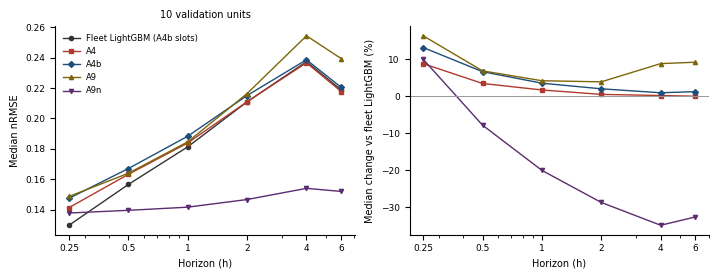

In [5]:
import matplotlib.pyplot as plt
A._style()
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
hx = np.array(FC.H) * 0.25
lg = med[med.row == 'A4b'].set_index('h').loc[FC.H, 'nRMSE_lgb_same_slots']
ax[0].plot(hx, lg, color='0.2', marker='o', ms=3, lw=1, label='Fleet LightGBM (A4b slots)')
sty = {'A4': ('#b03a2e', 's'), 'A4b': ('#1f4e79', 'D'), 'A9': ('#7d6608', '^'), 'A9n': ('#5b2c6f', 'v')}
for row, (c, mk) in sty.items():
    z = med[med.row == row].set_index('h').reindex(FC.H)
    ax[0].plot(hx, z['nRMSE_row'], color=c, marker=mk, ms=3, lw=1, label=row)
    ax[1].plot(hx, z['rel_nRMSE_vs_lgb_pct'], color=c, marker=mk, ms=3, lw=1, label=row)
for a_ in ax:
    a_.set_xscale('log'); a_.set_xticks(hx); a_.set_xticklabels(['0.25', '0.5', '1', '2', '4', '6']); a_.set_xlabel('Horizon (h)')
ax[0].set_ylabel('Median nRMSE'); ax[0].legend(frameon=False, fontsize=6)
ax[1].axhline(0, color='0.6', lw=0.7); ax[1].set_ylabel('Median change vs fleet LightGBM (%)')
ax[0].set_title('10 validation units', fontsize=7); fig.tight_layout()

## Outputs (all-or-nothing)

In [6]:
summary = {'notebook': 'NB5d_sources', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'lgb_config_sha256': nb5['lgb_config_sha256'], 'sensor_config_sha256': nb4['sensor_config_sha256'],
           'rows': {k: {'source': s_, 'model': m_} for k, (s_, m_) in ROWS.items()},
           'prior_check_max_abs_diff': PRIOR_DIFF,
           'median_nRMSE_1h': med[med.h == C.PRIMARY_HORIZON].set_index('row')['nRMSE_row'].round(5).to_dict(),
           'median_rel_vs_lgb_pct_1h': med[med.h == C.PRIMARY_HORIZON].set_index('row')['rel_nRMSE_vs_lgb_pct'].round(2).to_dict(),
           'units_row_better_1h': med[med.h == C.PRIMARY_HORIZON].set_index('row')['units_row_better'].to_dict(),
           'coverage_median_1h': med[med.h == C.PRIMARY_HORIZON].set_index('row')['coverage_median'].round(4).to_dict()}
out = A.write_outputs('nb5d_sources', {'scores': sc, 'medians': med, 'prior_check': pchk}, summary,
                      {'fig_sources': fig}, parquet={'forecasts': FCX})
print(json.dumps({k: summary[k] for k in ('median_nRMSE_1h', 'median_rel_vs_lgb_pct_1h', 'units_row_better_1h')}, indent=1))
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

{
 "median_nRMSE_1h": {
  "A4": 0.18393,
  "A4b": 0.18837,
  "A9": 0.18464,
  "A9n": 0.14174
 },
 "median_rel_vs_lgb_pct_1h": {
  "A4": 1.66,
  "A4b": 3.49,
  "A9": 4.16,
  "A9n": -20.03
 },
 "units_row_better_1h": {
  "A4": 0,
  "A4b": 0,
  "A9": 1,
  "A9n": 10
 }
}
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5d_sources | ['figures', 'forecasts.parquet', 'medians.csv', 'prior_check.csv', 'scores.csv', 'summary.json']
